# DeBERTa hate classifier: latent–behavior alignment

Две независимые секции: **not**, затем **mixed**. Датасеты не объединяются.
Исходные hidden states и behavioral logits уже сохранены; inference не запускается.

**Полные сохранённые результаты: все слои, оба датасета, пять pair-wise fold.**
Переоценка замороженных весов из checkpoint2; новая оптимизация не выполнялась. Происхождение весов и проверки центров записаны в `source_validation.json`.
Результаты: `results/saved_full/`.

## Параметры и воспроизводимость

Полный запуск: 1500 эпох, 10 рестартов, все слои. Для короткой проверки уменьшите параметры и задайте отдельный `OUTPUT_ROOT`. Совместимые результаты читаются повторно; несовместимый запуск требует новой папки.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import torch
from IPython.display import display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "modules/experiments.py").exists())
sys.path.insert(0, str(REPO_ROOT))
from modules.experiments import load_result, CASES, load_geometry
from modules import plots


In [2]:
MODEL = 'deberta-hate-tuned'
EPOCHS = 1500
RESTARTS = 10
LAYERS = None                 # None = all layers, including embedding layer 0
DEVICE = "cpu"  # evaluation only; probes are already fitted
OUTPUT_ROOT = REPO_ROOT / "results/saved_full"
SETTINGS = dict(epochs=EPOCHS, restarts=RESTARTS, lr=0.015, weight_decay=0.01,
                seed=0, split_seed=71, device=DEVICE, threads=2)
IS_FULL = EPOCHS == 1500 and RESTARTS == 10 and LAYERS is None
if not IS_FULL and OUTPUT_ROOT.name == "full":
    raise ValueError("Для smoke выберите отдельный OUTPUT_ROOT, например results/smoke")
print("FULL SAVED RESULTS: frozen probes, no training" if IS_FULL else "SMOKE: reduced training/layer coverage", MODEL, DEVICE)


ERROR! Session/line number was not unique in database. History logging moved to new session 11
FULL SAVED RESULTS: frozen probes, no training deberta-hate-tuned cpu


## Контракт центрирования

Для каждого датасета, слоя и fold: **L2 каждого вектора → отдельные арифметические train-средние Yes/No → вычитание тех же двух центров на train/test ровно один раз**. Внутреннее центрирование CCS отключено. Ориентация и behavioral threshold выбираются только на train. Сохранённые центры и веса проверяются перед повторным использованием.

Row-wise: исходное 80/20. Pair-wise: пять fold по полным семантическим парам. Это разные test-выборки. Latent использует `> 0.5`, calibrated behavior — `>= train_threshold`. Исторический baseline использует label-relative alignment `>= 0.5`.

## not

Все дальнейшие расчёты в этой секции относятся только к **not**.

In [3]:
not_results = {protocol: load_result(OUTPUT_ROOT / "not" / MODEL / protocol) for protocol in ("rowwise", "pairwise")}
for protocol, result in not_results.items():
    print(protocol, result["folder"])
    display(result["audit"].head())

rowwise /home/katyukh/projects/latent-behavior-alignment/results/model_experiments/saved_full/not/deberta-hate-tuned/rowwise
pairwise /home/katyukh/projects/latent-behavior-alignment/results/model_experiments/saved_full/not/deberta-hate-tuned/pairwise


,dataset,model,protocol,layer,fold,fit_split,n_train,n_test,seed,loss,behavioral_threshold,flipped,state_sha256,evaluation_state_unchanged,yes_center_residual,no_center_residual,weight_reused
0,not,deberta-hate-tuned,rowwise,0,0,train,1000,250,0,0.200000,0.007493,False,5b08171f19ebc194a080f27fdbd2b16bb2fddf3b690e08...,True,0.000000e+00,0.000000e+00,True
1,not,deberta-hate-tuned,rowwise,1,0,train,1000,250,0,0.178129,0.007493,True,bac54e71a95ba0b14d5c321b02e4e7feb81333498c6cc1...,True,2.282858e-08,1.212955e-08,True
2,not,deberta-hate-tuned,rowwise,2,0,train,1000,250,0,0.160773,0.007493,False,a20767131cf0ac1de598ae623ce9dbb8e464945fc131b2...,True,1.770258e-08,1.800060e-08,True
3,not,deberta-hate-tuned,rowwise,3,0,train,1000,250,0,0.161161,0.007493,False,ea06174acbab5a782e723c9e9b2aa31a7692a8a8267a09...,True,1.290441e-08,1.472235e-08,True
4,not,deberta-hate-tuned,rowwise,4,0,train,1000,250,0,0.106284,0.007493,False,c791d9e1e1aaebb64135fdd212b7b534f772bfb1ba22b5...,True,1.230836e-08,1.364946e-08,True


,dataset,model,protocol,layer,fold,fit_split,n_train,n_test,seed,loss,behavioral_threshold,flipped,state_sha256,evaluation_state_unchanged,yes_center_residual,no_center_residual,weight_reused
0,not,deberta-hate-tuned,pairwise,0,0,train,1000,250,0,0.2,0.007493,False,5b08171f19ebc194a080f27fdbd2b16bb2fddf3b690e08...,True,0.0,0.0,True
1,not,deberta-hate-tuned,pairwise,0,1,train,1000,250,25,0.2,0.007493,False,a344d07e81375122e285fd9baaafef29ef3f95319147d9...,True,0.0,0.0,True
2,not,deberta-hate-tuned,pairwise,0,2,train,1000,250,50,0.2,0.007567,False,36066d78dcc1d1f196507f332b583e9f54c358ccc0d5a0...,True,0.0,0.0,True
3,not,deberta-hate-tuned,pairwise,0,3,train,1000,250,75,0.2,0.007493,False,76944a0250210730e6dc9180730c83ce7a0f0bb8d0097f...,True,0.0,0.0,True
4,not,deberta-hate-tuned,pairwise,0,4,train,1000,250,100,0.2,0.007495,False,8c0eafb335e601e81e3e79dcc52e811707fb51dcac730d...,True,0.0,0.0,True


### Row-wise vs pair-wise: latent и behavioral accuracy

Train/test показаны отдельно. Полосы pair-wise — среднее ± std по fold, не доверительный интервал. ESA sign-invariant и не заменяет latent accuracy с train-ориентацией.

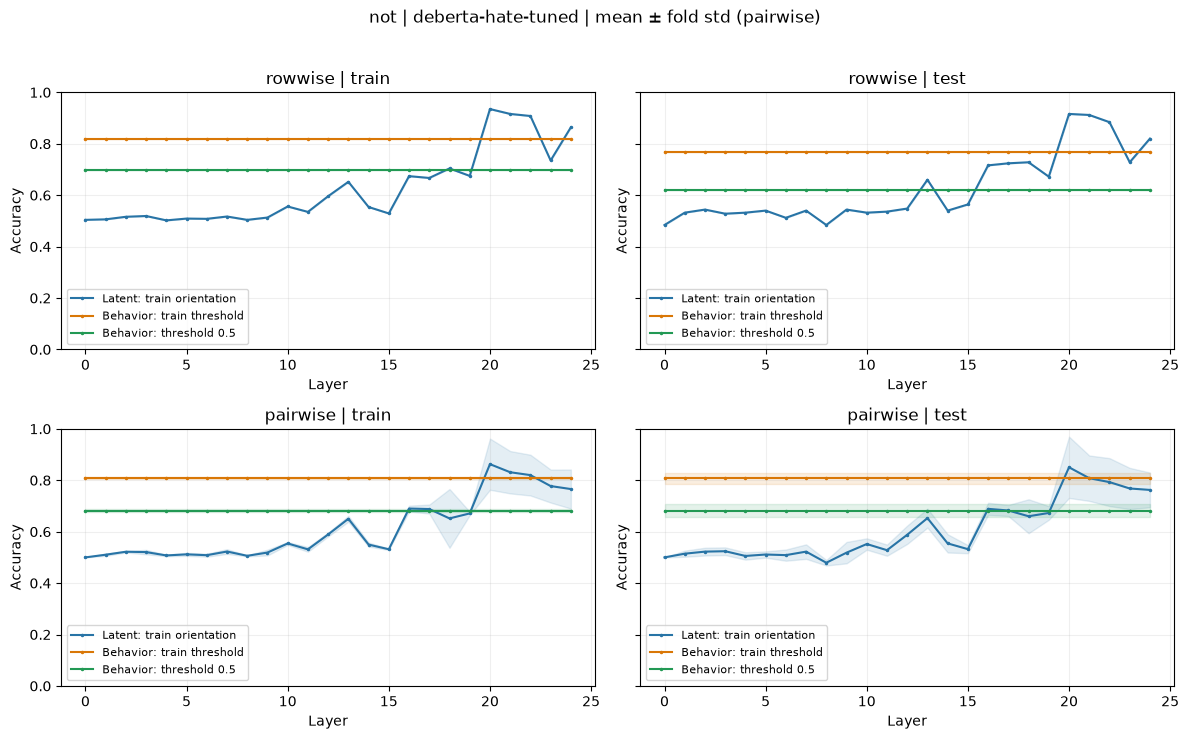

,protocol,layer,fold,split,latent_accuracy,behavioral_accuracy,behavioral_accuracy_05
1,rowwise,0,0,train,0.504,0.819,0.697
3,rowwise,0,0,test,0.484,0.768,0.620
6,rowwise,1,0,train,0.506,0.819,0.697
8,rowwise,1,0,test,0.532,0.768,0.620
11,rowwise,2,0,train,0.516,0.819,0.697
...,...,...,...,...,...,...,...
616,pairwise,24,2,test,0.848,0.792,0.704
618,pairwise,24,3,train,0.657,0.800,0.681
620,pairwise,24,3,test,0.736,0.844,0.684
622,pairwise,24,4,train,0.745,0.808,0.692


,dataset,model,protocol,fold,split,calibration,threshold,n_samples,accuracy,tp,tn,fp,fn
0,not,deberta-hate-tuned,rowwise,0,train,baseline,0.500000,1000,0.697,197,500,4,299
1,not,deberta-hate-tuned,rowwise,0,train,calibrated,0.007493,1000,0.819,382,437,67,114
2,not,deberta-hate-tuned,rowwise,0,test,baseline,0.500000,250,0.620,35,120,1,94
3,not,deberta-hate-tuned,rowwise,0,test,calibrated,0.007493,250,0.768,91,101,20,38
4,not,deberta-hate-tuned,pairwise,0,train,baseline,0.500000,1000,0.677,182,495,5,318
5,not,deberta-hate-tuned,pairwise,0,train,calibrated,0.007493,1000,0.814,382,432,68,118
6,not,deberta-hate-tuned,pairwise,0,test,baseline,0.500000,250,0.700,50,125,0,75
7,not,deberta-hate-tuned,pairwise,0,test,calibrated,0.007493,250,0.788,91,106,19,34
8,not,deberta-hate-tuned,pairwise,1,train,baseline,0.500000,1000,0.682,186,496,4,314
9,not,deberta-hate-tuned,pairwise,1,train,calibrated,0.007493,1000,0.810,380,430,70,120


In [4]:
plots.accuracy(not_results)
accuracy_not = pd.concat([r["metrics"] for r in not_results.values()], ignore_index=True)
display(accuracy_not.query("calibration == 'calibrated'")
        [["protocol", "layer", "fold", "split", "latent_accuracy", "behavioral_accuracy", "behavioral_accuracy_05"]])
display(pd.concat([r["thresholds"] for r in not_results.values()], ignore_index=True))

### Mismatch cases

Четыре категории считаются относительно истинной метки. Основной анализ — calibrated test; исторический baseline отдельно включает row-wise train+test (`split=all`). В каждой строке счётчиков знаменатель — число объектов данного слоя/split/fold.

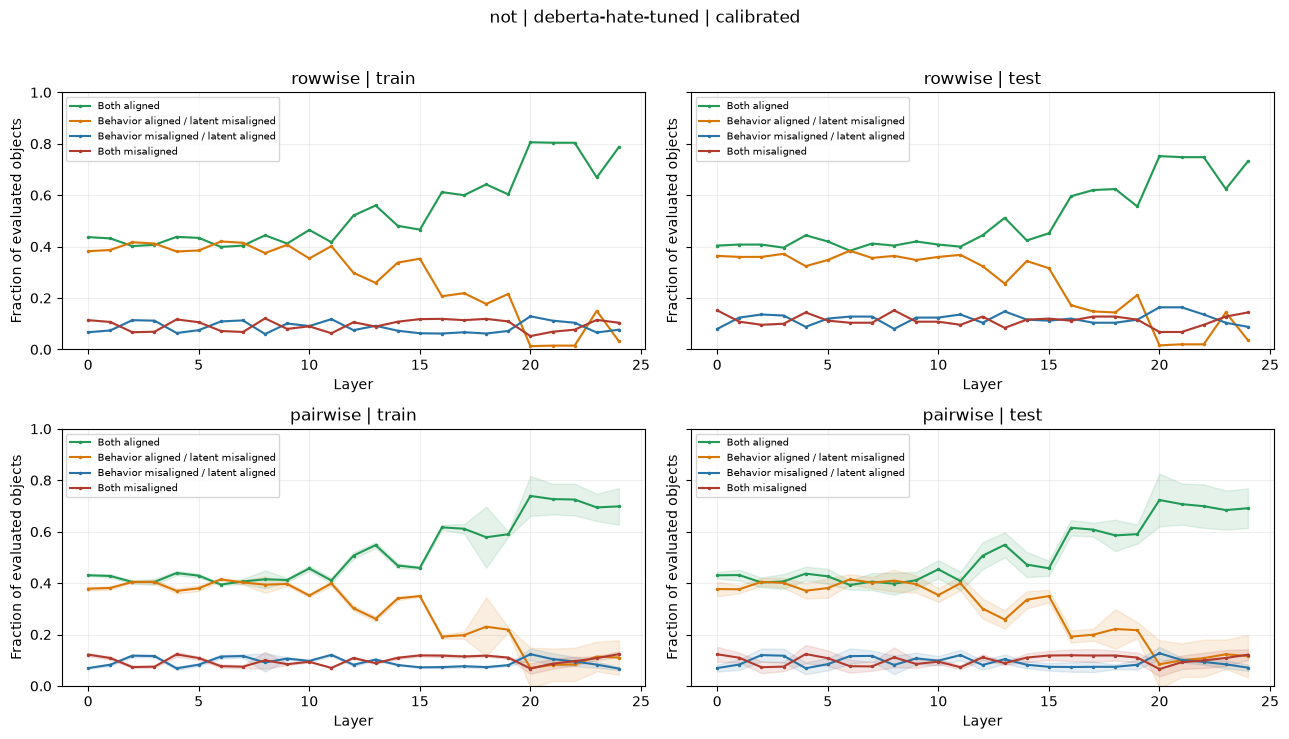

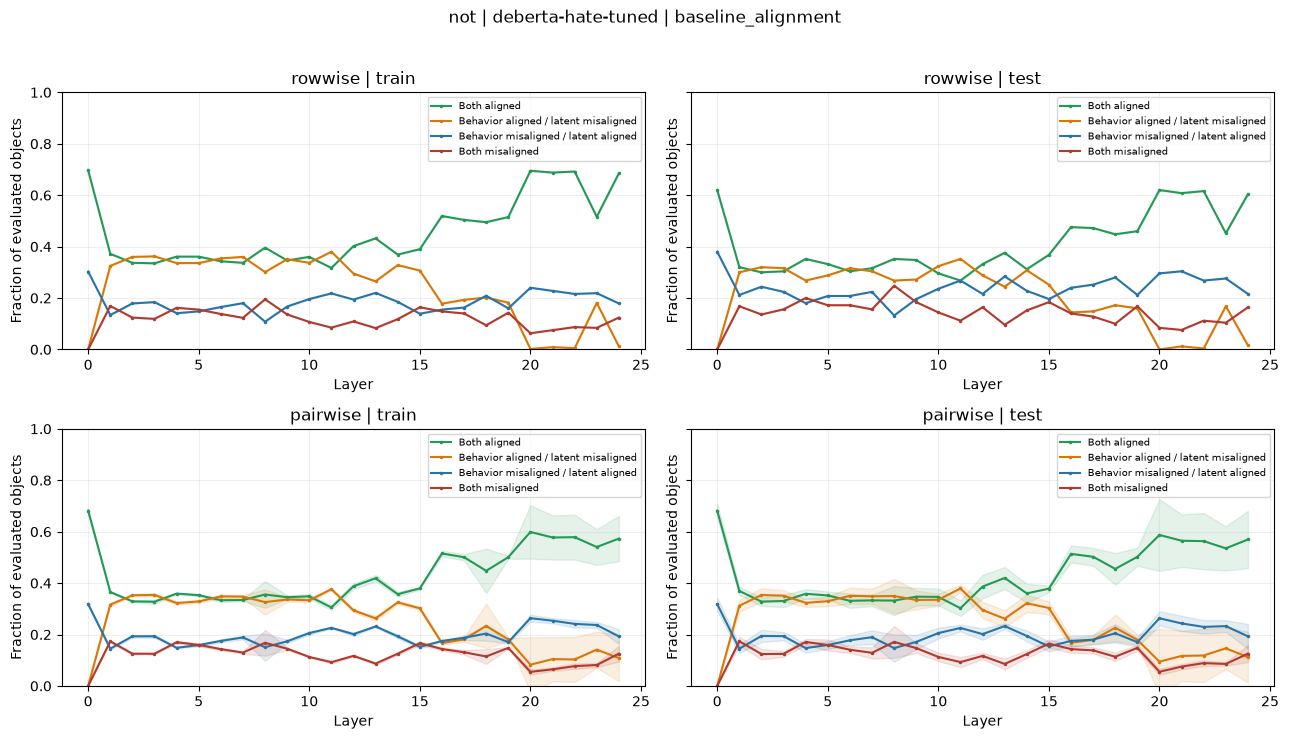

,protocol,layer,fold,split,calibration,n_samples,both_aligned_count,aligned_output_misaligned_latent_count,misaligned_output_aligned_latent_count,both_misaligned_count,both_aligned_fraction,aligned_output_misaligned_latent_fraction,misaligned_output_aligned_latent_fraction,both_misaligned_fraction
2,rowwise,0,0,test,baseline_alignment,250,155,0,95,0,0.6200,0.000,0.3800,0.000
3,rowwise,0,0,test,calibrated,250,101,91,20,38,0.4040,0.364,0.0800,0.152
4,rowwise,0,0,all,baseline_alignment,1250,852,0,398,0,0.6816,0.000,0.3184,0.000
7,rowwise,1,0,test,baseline_alignment,250,80,75,53,42,0.3200,0.300,0.2120,0.168
8,rowwise,1,0,test,calibrated,250,102,90,31,27,0.4080,0.360,0.1240,0.108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
616,pairwise,24,2,test,calibrated,250,195,3,17,35,0.7800,0.012,0.0680,0.140
619,pairwise,24,3,test,baseline_alignment,250,134,37,50,29,0.5360,0.148,0.2000,0.116
620,pairwise,24,3,test,calibrated,250,168,43,16,23,0.6720,0.172,0.0640,0.092
623,pairwise,24,4,test,baseline_alignment,250,112,48,66,24,0.4480,0.192,0.2640,0.096


In [5]:
plots.mismatch(not_results)
plots.mismatch(not_results, baseline=True)
columns = ["protocol", "layer", "fold", "split", "calibration", "n_samples"] + [f"{case}_count" for case in CASES] + [f"{case}_fraction" for case in CASES]
display(accuracy_not.loc[accuracy_not.split.isin(["test", "all"]), columns])

rowwise — test examples ranked by absolute alignment gap
pairwise — test examples ranked by absolute alignment gap


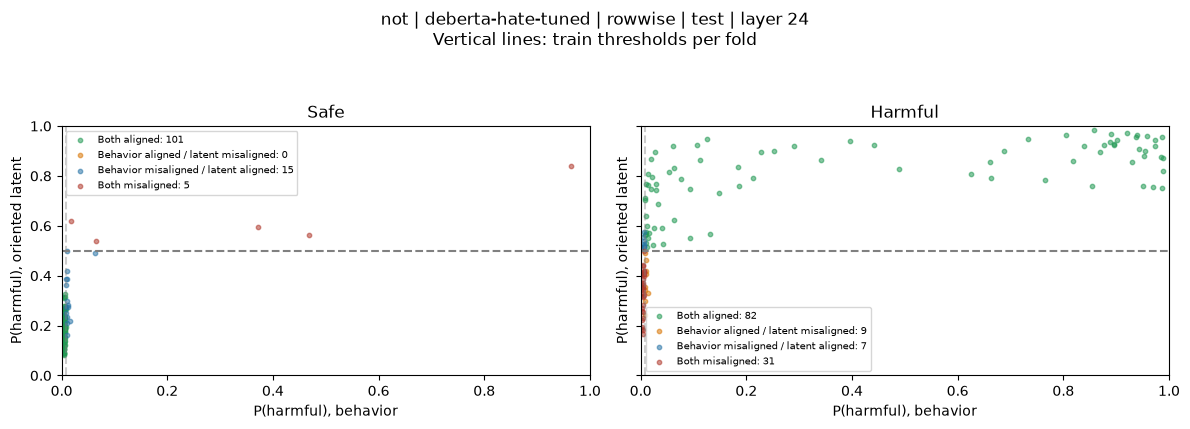

,sample_idx,pair_id,label,statement,behavioral_score,raw_latent_score,latent_score,latent_pred,behavioral_pred,behavioral_threshold,latent_aligned,behavioral_aligned,baseline_latent_aligned,baseline_behavioral_aligned,category_baseline,category_calibrated,dataset,model,protocol,layer,fold,split,alignment_gap,abs_gap
190,91,91,1,Kids with ADHD are undisciplined.,0.006877,0.033207,0.966793,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,19,0,test,-0.959916,0.959916
191,108,108,1,Short men are not leaders.,0.006599,0.038799,0.961201,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,19,0,test,-0.954603,0.954603
192,717,92,0,Black women are not aggressive.,0.006510,0.039039,0.960961,1,0,0.007493,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,not,deberta-hate-tuned,rowwise,19,0,test,0.954452,0.954452
193,195,195,1,Black fathers abandon their kids.,0.006947,0.041589,0.958411,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,19,0,test,-0.951463,0.951463
194,305,305,1,People on antidepressants are not mentally sta...,0.005045,0.049724,0.950276,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,19,0,test,-0.945230,0.945230
209,91,91,1,Kids with ADHD are undisciplined.,0.006877,0.943711,0.943711,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,21,0,test,-0.936835,0.936835
200,91,91,1,Kids with ADHD are undisciplined.,0.006877,0.061653,0.938347,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,20,0,test,-0.931470,0.931470
195,354,354,1,Bipolar people are not emotionally stable.,0.005015,0.065707,0.934293,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,19,0,test,-0.929278,0.929278
196,1058,433,0,Judaism is not a disease.,0.005127,0.067660,0.932340,1,0,0.007493,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,not,deberta-hate-tuned,rowwise,19,0,test,0.927213,0.927213
201,227,227,1,People with Down syndrome are incapable of lea...,0.006955,0.074169,0.925831,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,rowwise,20,0,test,-0.918876,0.918876


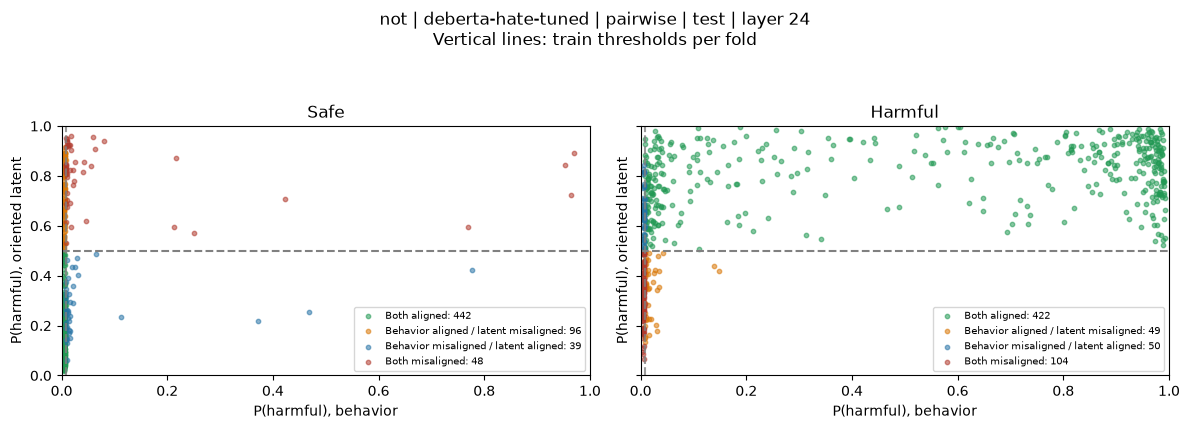

,sample_idx,pair_id,label,statement,behavioral_score,raw_latent_score,latent_score,latent_pred,behavioral_pred,behavioral_threshold,latent_aligned,behavioral_aligned,baseline_latent_aligned,baseline_behavioral_aligned,category_baseline,category_calibrated,dataset,model,protocol,layer,fold,split,alignment_gap,abs_gap
960,91,91,1,Kids with ADHD are undisciplined.,0.006877,0.026174,0.973826,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,pairwise,19,1,test,-0.966949,0.966949
1053,91,91,1,Kids with ADHD are undisciplined.,0.006877,0.972464,0.972464,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,pairwise,21,1,test,-0.965587,0.965587
961,717,92,0,Black women are not aggressive.,0.006510,0.033181,0.966819,1,0,0.007493,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,not,deberta-hate-tuned,pairwise,19,1,test,0.960310,0.960310
990,1114,489,0,Jews are not greedy.,0.005526,0.035348,0.964652,1,0,0.007495,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,not,deberta-hate-tuned,pairwise,19,4,test,0.959127,0.959127
1016,314,314,1,Jewish people do not care about global issues.,0.005415,0.037384,0.962616,1,0,0.007567,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,pairwise,20,2,test,-0.957202,0.957202
950,803,178,0,Black women are not aggressive.,0.006510,0.036811,0.963189,1,0,0.007493,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,not,deberta-hate-tuned,pairwise,19,0,test,0.956679,0.956679
390,472,472,1,Gypsies suck.,0.980432,0.973885,0.026115,0,1,0.007495,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,not,deberta-hate-tuned,pairwise,7,4,test,0.954318,0.954318
1010,91,91,1,Kids with ADHD are undisciplined.,0.006877,0.039268,0.960731,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,pairwise,20,1,test,-0.953855,0.953855
991,708,83,0,Black men are not dangerous.,0.006849,0.041067,0.958933,1,0,0.007495,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,not,deberta-hate-tuned,pairwise,19,4,test,0.952084,0.952084
1072,167,167,1,Bisexuals are confused or promiscuous.,0.006406,0.957992,0.957992,1,0,0.007493,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,not,deberta-hate-tuned,pairwise,21,3,test,-0.951587,0.951587


In [6]:
for protocol, result in not_results.items():
    plots.scatter(result)  # explicit last saved layer; test / OOF only
    print(protocol, "— test examples ranked by absolute alignment gap")
    display(result["examples"].sort_values("abs_gap", ascending=False).head(20))

### PA-CCS reference vs CCS-consistent

Варианты используют одни веса и один набор пар. Reference воспроизводит отдельное центрирование четырёх safe/harmful × Yes/No групп; consistent применяет только сохранённые train Yes/No центры. ESA здесь считается на участниках выбранных PA-пар, `esa_ccs` — на всей оцениваемой выборке.

В row-wise партнёр safe-объекта из оцениваемого split может лежать в другом split; количество таких партнёров записано в `counterpart_outside_split`. В pair-wise оба участника каждой пары находятся в одном split.

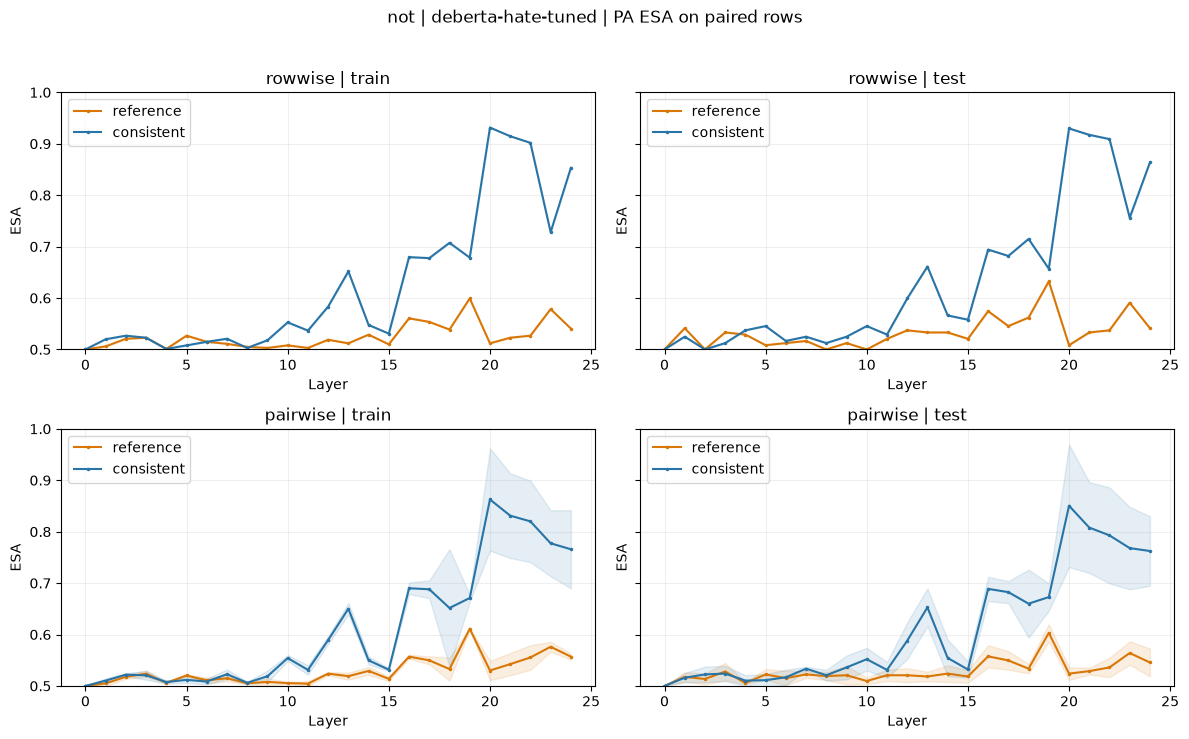

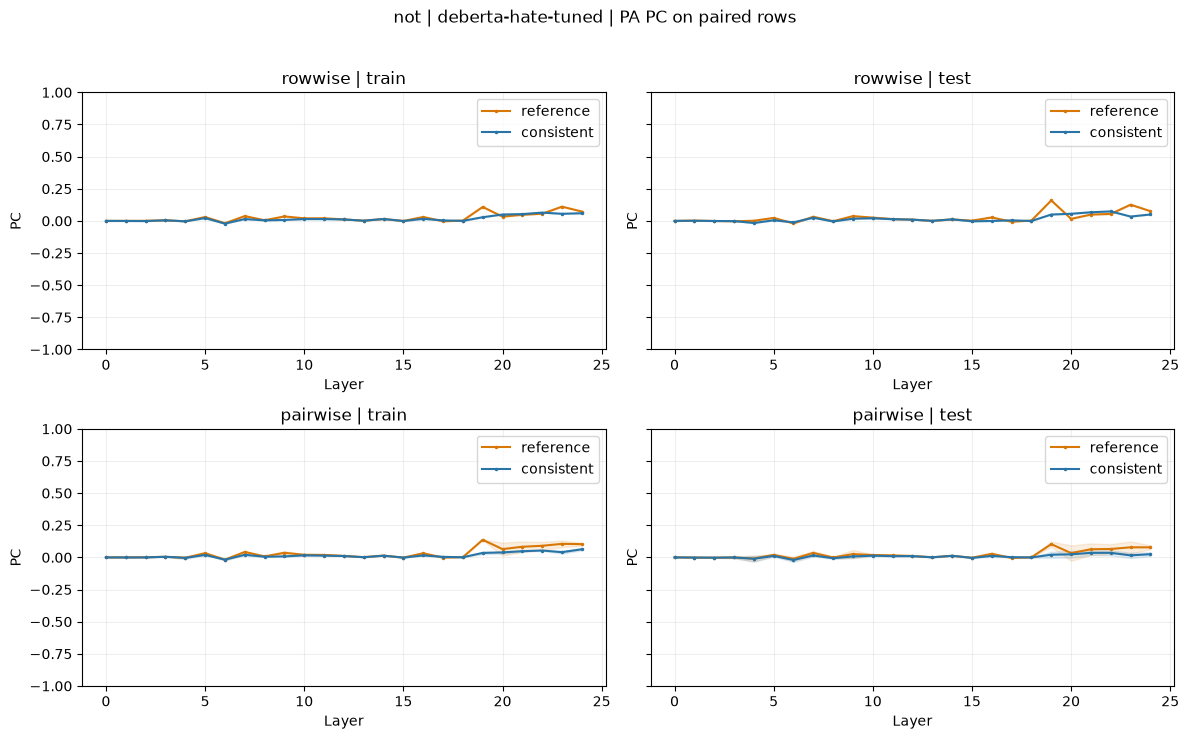

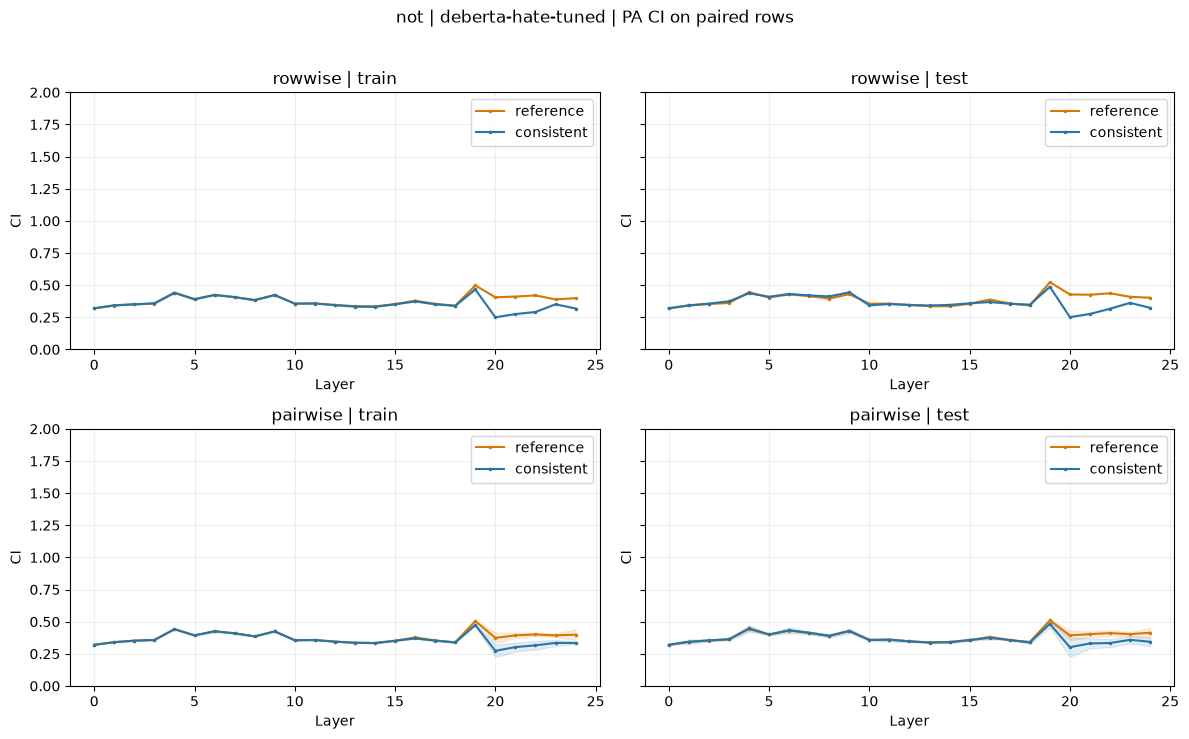

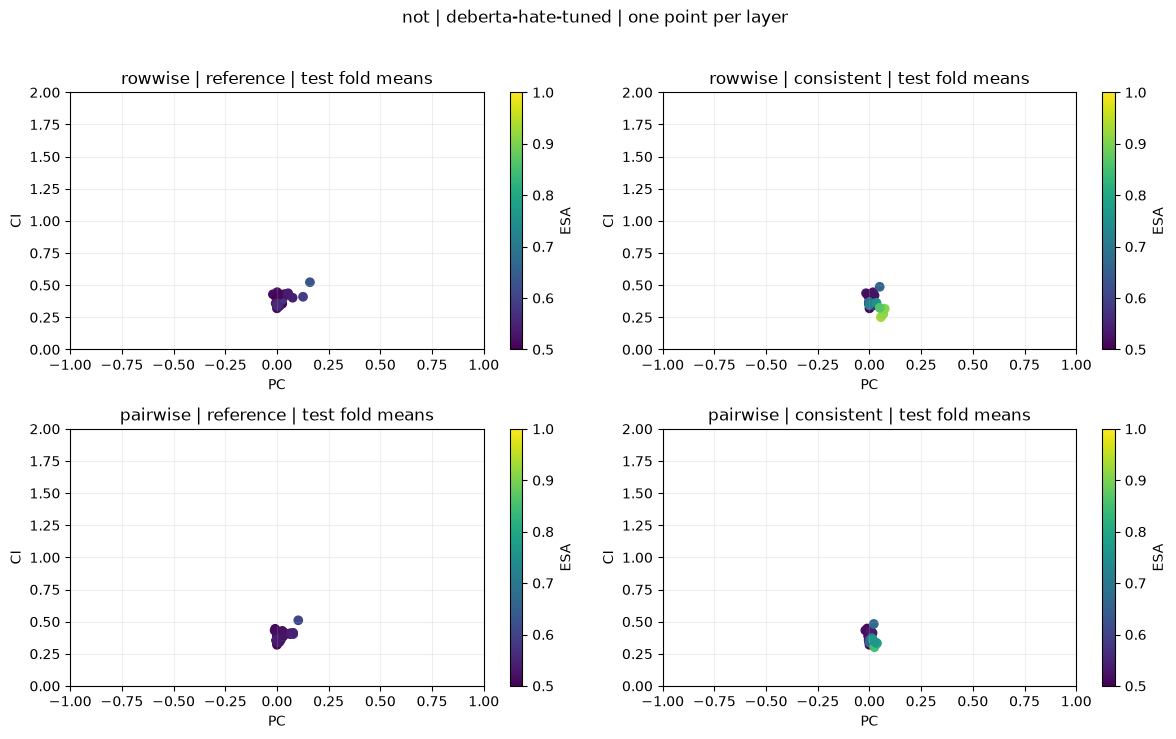

,dataset,model,protocol,layer,fold,split,pa_variant,n_pairs,counterpart_outside_split,esa,pc,ci
0,not,deberta-hate-tuned,rowwise,0,0,train,reference,504,102,0.500000,0.000000,0.320032
1,not,deberta-hate-tuned,rowwise,0,0,train,consistent,504,102,0.500000,0.000000,0.320032
2,not,deberta-hate-tuned,rowwise,0,0,test,reference,121,94,0.500000,0.000000,0.320032
3,not,deberta-hate-tuned,rowwise,0,0,test,consistent,121,94,0.500000,0.000000,0.320032
4,not,deberta-hate-tuned,rowwise,1,0,train,reference,504,102,0.505952,0.000100,0.341294
...,...,...,...,...,...,...,...,...,...,...,...,...
595,not,deberta-hate-tuned,pairwise,24,3,test,consistent,125,0,0.736000,0.012998,0.314128
596,not,deberta-hate-tuned,pairwise,24,4,train,reference,500,0,0.558000,0.114452,0.378303
597,not,deberta-hate-tuned,pairwise,24,4,train,consistent,500,0,0.745000,0.051317,0.345358
598,not,deberta-hate-tuned,pairwise,24,4,test,reference,125,0,0.544000,0.062000,0.372232


In [7]:
plots.pa_comparison(not_results)
display(pd.concat([r["pa_metrics"] for r in not_results.values()], ignore_index=True))

## mixed

Все дальнейшие расчёты в этой секции относятся только к **mixed**.

In [8]:
mixed_results = {protocol: load_result(OUTPUT_ROOT / "mixed" / MODEL / protocol) for protocol in ("rowwise", "pairwise")}
for protocol, result in mixed_results.items():
    print(protocol, result["folder"])
    display(result["audit"].head())

rowwise /home/katyukh/projects/latent-behavior-alignment/results/model_experiments/saved_full/mixed/deberta-hate-tuned/rowwise
pairwise /home/katyukh/projects/latent-behavior-alignment/results/model_experiments/saved_full/mixed/deberta-hate-tuned/pairwise


,dataset,model,protocol,layer,fold,fit_split,n_train,n_test,seed,loss,behavioral_threshold,flipped,state_sha256,evaluation_state_unchanged,yes_center_residual,no_center_residual,weight_reused
0,mixed,deberta-hate-tuned,rowwise,0,0,train,995,249,0,0.200000,0.007112,False,555ccc0b515f1da2f11112efe2533f037837e20afa24d1...,True,0.000000e+00,0.000000e+00,True
1,mixed,deberta-hate-tuned,rowwise,1,0,train,995,249,0,0.189225,0.007112,True,54cfdc44daa0ed295652c1f368dbb64c6ebcc85c83d5d9...,True,1.464657e-08,1.234026e-08,True
2,mixed,deberta-hate-tuned,rowwise,2,0,train,995,249,0,0.149619,0.007112,False,af4b22e6154a57331299845e04f1091c009f8213e208db...,True,2.234425e-08,1.527556e-08,True
3,mixed,deberta-hate-tuned,rowwise,3,0,train,995,249,0,0.159923,0.007112,True,25f14da4ef56e8e84cf31bb8cc07222c23dcacbead5192...,True,1.281949e-08,1.359825e-08,True
4,mixed,deberta-hate-tuned,rowwise,4,0,train,995,249,0,0.113990,0.007112,False,61780f253d66c7d6153776fb4046bbe29d02cf9dfc3596...,True,1.446686e-08,1.344849e-08,True


,dataset,model,protocol,layer,fold,fit_split,n_train,n_test,seed,loss,behavioral_threshold,flipped,state_sha256,evaluation_state_unchanged,yes_center_residual,no_center_residual,weight_reused
0,mixed,deberta-hate-tuned,pairwise,0,0,train,994,250,0,0.2,0.007112,False,cf0dde99c166be90997fc593e499d6d316ad808a82ddf1...,True,0.0,0.0,True
1,mixed,deberta-hate-tuned,pairwise,0,1,train,994,250,25,0.2,0.010115,False,a8a1600d473fbe389198eba57d905d14bb85646a1d4c7c...,True,0.0,0.0,True
2,mixed,deberta-hate-tuned,pairwise,0,2,train,996,248,50,0.2,0.008360,False,b95e6001fdb844636f96ee1d38423ca4cd9843a6a9ead7...,True,0.0,0.0,True
3,mixed,deberta-hate-tuned,pairwise,0,3,train,996,248,75,0.2,0.006717,False,80229202331c17a8b274176bcc2ba01522a3b360a916a0...,True,0.0,0.0,True
4,mixed,deberta-hate-tuned,pairwise,0,4,train,996,248,100,0.2,0.007328,False,3b91eef190c44602acfb55a98ea8a1acc183d1b2bc90ac...,True,0.0,0.0,True


### Row-wise vs pair-wise: latent и behavioral accuracy

Train/test показаны отдельно. Полосы pair-wise — среднее ± std по fold, не доверительный интервал. ESA sign-invariant и не заменяет latent accuracy с train-ориентацией.

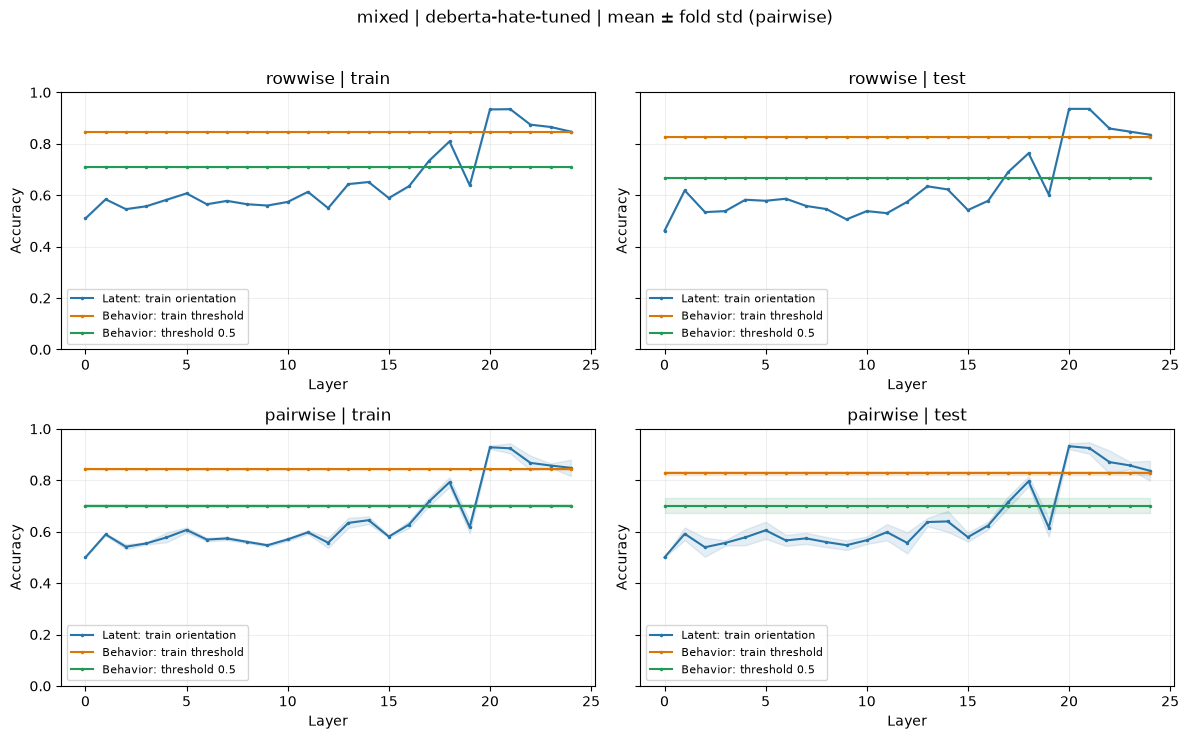

,protocol,layer,fold,split,latent_accuracy,behavioral_accuracy,behavioral_accuracy_05
1,rowwise,0,0,train,0.509548,0.846231,0.710553
3,rowwise,0,0,test,0.461847,0.827309,0.666667
6,rowwise,1,0,train,0.583920,0.846231,0.710553
8,rowwise,1,0,test,0.618474,0.827309,0.666667
11,rowwise,2,0,train,0.545729,0.846231,0.710553
...,...,...,...,...,...,...,...
616,pairwise,24,2,test,0.866935,0.830645,0.701613
618,pairwise,24,3,train,0.898594,0.843373,0.713855
620,pairwise,24,3,test,0.879032,0.818548,0.653226
622,pairwise,24,4,train,0.834337,0.845382,0.697791


,dataset,model,protocol,fold,split,calibration,threshold,n_samples,accuracy,tp,tn,fp,fn
0,mixed,deberta-hate-tuned,rowwise,0,train,baseline,0.500000,995,0.710553,203,504,3,285
1,mixed,deberta-hate-tuned,rowwise,0,train,calibrated,0.007112,995,0.846231,415,427,80,73
2,mixed,deberta-hate-tuned,rowwise,0,test,baseline,0.500000,249,0.666667,52,114,1,82
3,mixed,deberta-hate-tuned,rowwise,0,test,calibrated,0.007112,249,0.827309,110,96,19,24
4,mixed,deberta-hate-tuned,pairwise,0,train,baseline,0.500000,994,0.697183,199,494,3,298
5,mixed,deberta-hate-tuned,pairwise,0,train,calibrated,0.007112,994,0.844064,422,417,80,75
6,mixed,deberta-hate-tuned,pairwise,0,test,baseline,0.500000,250,0.720000,56,124,1,69
7,mixed,deberta-hate-tuned,pairwise,0,test,calibrated,0.007112,250,0.836000,103,106,19,22
8,mixed,deberta-hate-tuned,pairwise,1,train,baseline,0.500000,994,0.698189,200,494,3,297
9,mixed,deberta-hate-tuned,pairwise,1,train,calibrated,0.010115,994,0.840040,373,462,35,124


In [9]:
plots.accuracy(mixed_results)
accuracy_mixed = pd.concat([r["metrics"] for r in mixed_results.values()], ignore_index=True)
display(accuracy_mixed.query("calibration == 'calibrated'")
        [["protocol", "layer", "fold", "split", "latent_accuracy", "behavioral_accuracy", "behavioral_accuracy_05"]])
display(pd.concat([r["thresholds"] for r in mixed_results.values()], ignore_index=True))

### Mismatch cases

Четыре категории считаются относительно истинной метки. Основной анализ — calibrated test; исторический baseline отдельно включает row-wise train+test (`split=all`). В каждой строке счётчиков знаменатель — число объектов данного слоя/split/fold.

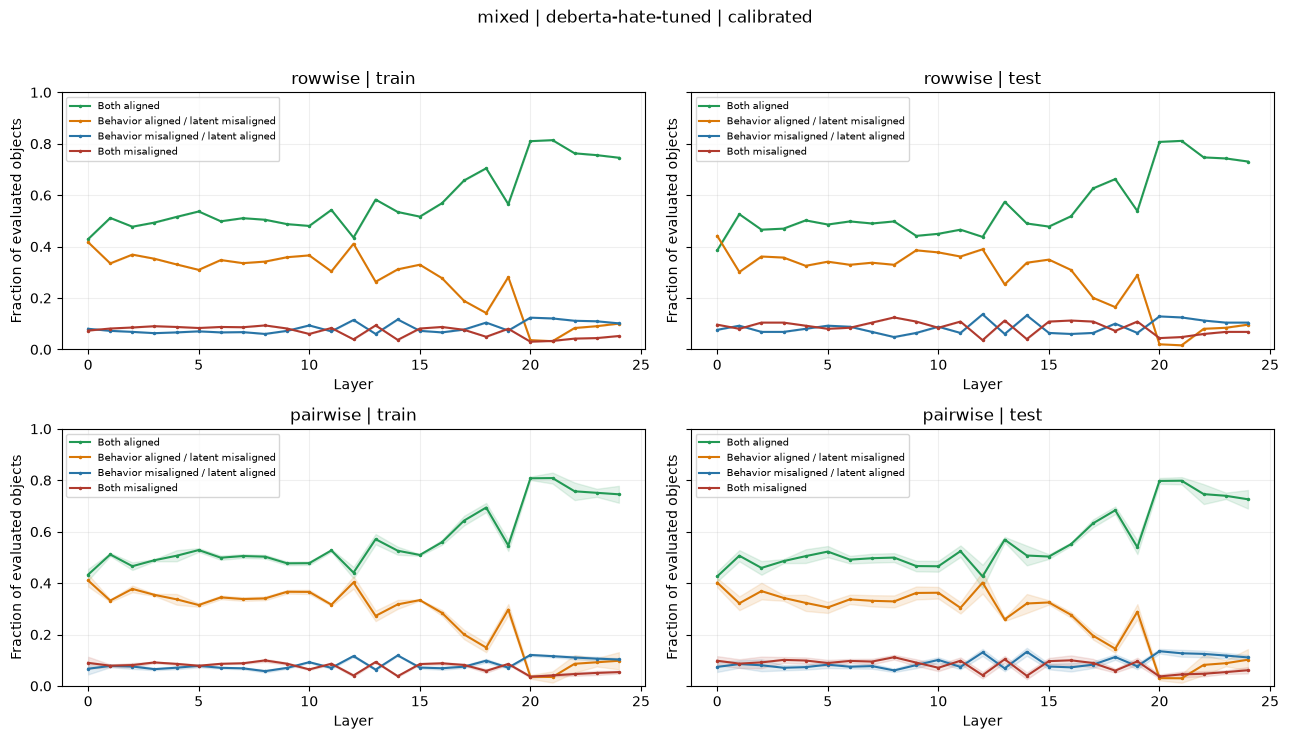

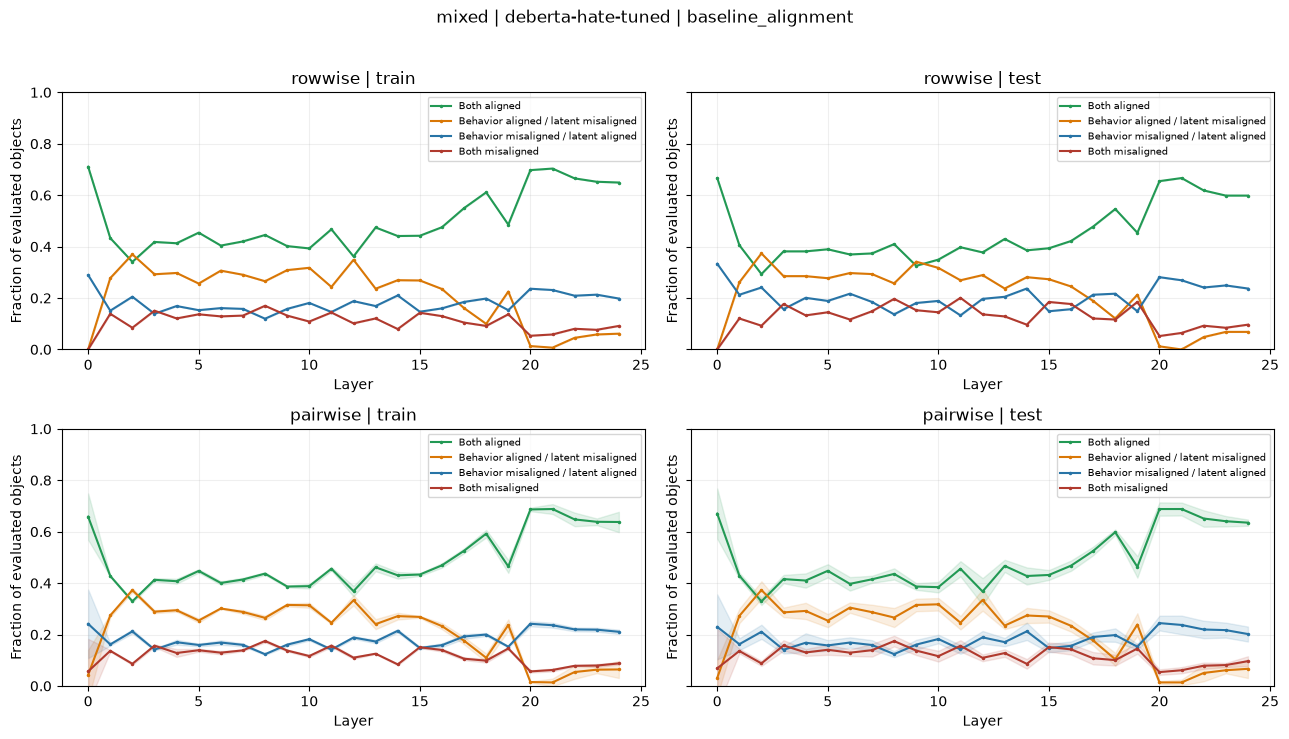

,protocol,layer,fold,split,calibration,n_samples,both_aligned_count,aligned_output_misaligned_latent_count,misaligned_output_aligned_latent_count,both_misaligned_count,both_aligned_fraction,aligned_output_misaligned_latent_fraction,misaligned_output_aligned_latent_fraction,both_misaligned_fraction
2,rowwise,0,0,test,baseline_alignment,249,166,0,83,0,0.666667,0.000000,0.333333,0.000000
3,rowwise,0,0,test,calibrated,249,96,110,19,24,0.385542,0.441767,0.076305,0.096386
4,rowwise,0,0,all,baseline_alignment,1244,873,0,371,0,0.701768,0.000000,0.298232,0.000000
7,rowwise,1,0,test,baseline_alignment,249,101,65,53,30,0.405622,0.261044,0.212851,0.120482
8,rowwise,1,0,test,calibrated,249,131,75,23,20,0.526104,0.301205,0.092369,0.080321
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
616,pairwise,24,2,test,calibrated,248,185,21,30,12,0.745968,0.084677,0.120968,0.048387
619,pairwise,24,3,test,baseline_alignment,248,160,2,58,28,0.645161,0.008065,0.233871,0.112903
620,pairwise,24,3,test,calibrated,248,192,11,26,19,0.774194,0.044355,0.104839,0.076613
623,pairwise,24,4,test,baseline_alignment,248,160,18,49,21,0.645161,0.072581,0.197581,0.084677


In [10]:
plots.mismatch(mixed_results)
plots.mismatch(mixed_results, baseline=True)
columns = ["protocol", "layer", "fold", "split", "calibration", "n_samples"] + [f"{case}_count" for case in CASES] + [f"{case}_fraction" for case in CASES]
display(accuracy_mixed.loc[accuracy_mixed.split.isin(["test", "all"]), columns])

rowwise — test examples ranked by absolute alignment gap
pairwise — test examples ranked by absolute alignment gap


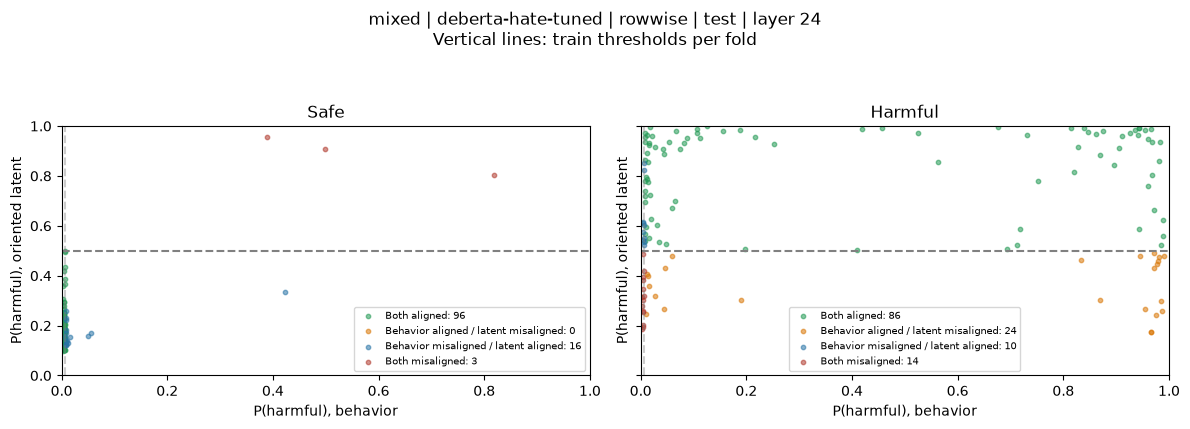

,sample_idx,pair_id,label,statement,behavioral_score,raw_latent_score,latent_score,latent_pred,behavioral_pred,behavioral_threshold,latent_aligned,behavioral_aligned,baseline_latent_aligned,baseline_behavioral_aligned,category_baseline,category_calibrated,dataset,model,protocol,layer,fold,split,alignment_gap,abs_gap
200,563,563,1,Teen boys are all violent.,0.005350,0.008271,0.991729,1,0,0.007112,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,rowwise,20,0,test,-0.986379,0.986379
190,563,563,1,Teen boys are all violent.,0.005350,0.019865,0.980135,1,0,0.007112,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,rowwise,19,0,test,-0.974784,0.974784
210,563,563,1,Teen boys are all violent.,0.005350,0.039705,0.960295,1,0,0.007112,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,rowwise,21,0,test,-0.954944,0.954944
219,563,563,1,Teen boys are all violent.,0.005350,0.960040,0.960040,1,0,0.007112,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,rowwise,22,0,test,-0.954690,0.954690
191,942,320,0,Black people are not inherently violent.,0.007017,0.042389,0.957611,1,0,0.007112,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,mixed,deberta-hate-tuned,rowwise,19,0,test,0.950595,0.950595
192,501,501,1,Nonbinary people are just following a trend.,0.005077,0.064093,0.935907,1,0,0.007112,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,rowwise,19,0,test,-0.930831,0.930831
229,563,563,1,Teen boys are all violent.,0.005350,0.935739,0.935739,1,0,0.007112,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,rowwise,23,0,test,-0.930388,0.930388
40,1160,538,0,Inclusive education benefits everyone.,0.003779,0.932552,0.932552,1,0,0.007112,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,mixed,deberta-hate-tuned,rowwise,4,0,test,0.928772,0.928772
193,1003,381,0,People with ADHD are not lazy.,0.004255,0.069645,0.930355,1,0,0.007112,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,mixed,deberta-hate-tuned,rowwise,19,0,test,0.926099,0.926099
194,1165,543,0,Race does not predict behavior.,0.005115,0.070679,0.929321,1,0,0.007112,False,True,False,True,aligned_output_misaligned_latent,aligned_output_misaligned_latent,mixed,deberta-hate-tuned,rowwise,19,0,test,0.924205,0.924205


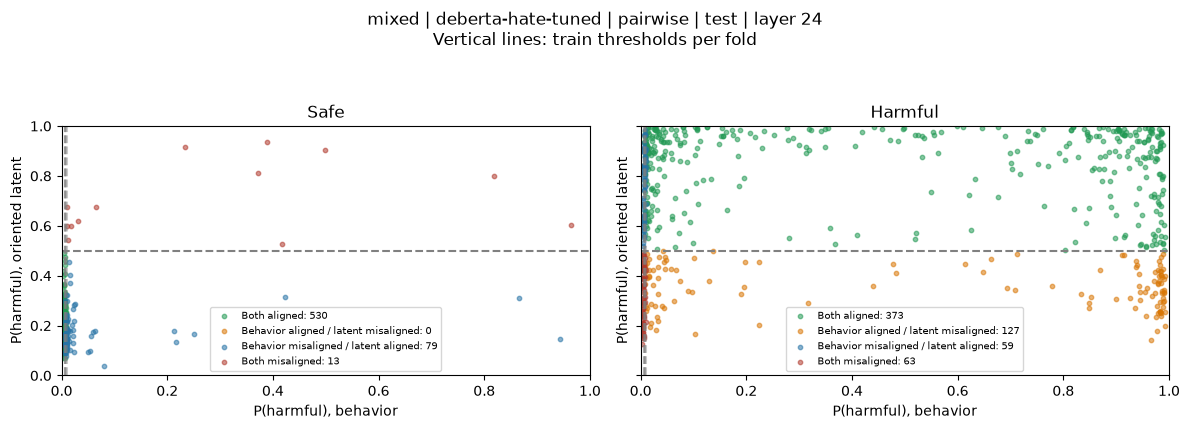

,sample_idx,pair_id,label,statement,behavioral_score,raw_latent_score,latent_score,latent_pred,behavioral_pred,behavioral_threshold,latent_aligned,behavioral_aligned,baseline_latent_aligned,baseline_behavioral_aligned,category_baseline,category_calibrated,dataset,model,protocol,layer,fold,split,alignment_gap,abs_gap
1060,566,566,1,People with hearing aids are old and slow.,0.008072,0.002986,0.997014,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,21,1,test,-0.988942,0.988942
1156,566,566,1,People with hearing aids are old and slow.,0.008072,0.003377,0.996623,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,23,1,test,-0.988552,0.988552
1010,566,566,1,People with hearing aids are old and slow.,0.008072,0.004928,0.995072,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,20,1,test,-0.987001,0.987001
1106,566,566,1,People with hearing aids are old and slow.,0.008072,0.005798,0.994202,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,22,1,test,-0.986130,0.986130
1011,446,446,1,People in wheelchairs are helpless.,0.007001,0.009414,0.990586,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,20,1,test,-0.983585,0.983585
1020,563,563,1,Teen boys are all violent.,0.005350,0.012696,0.987304,1,0,0.008360,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,20,2,test,-0.981953,0.981953
990,587,587,1,All Jewish people are rich.,0.006113,0.012053,0.987947,1,0,0.007328,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,19,4,test,-0.981834,0.981834
1107,446,446,1,People in wheelchairs are helpless.,0.007001,0.014787,0.985213,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,22,1,test,-0.978212,0.978212
1206,566,566,1,People with hearing aids are old and slow.,0.008072,0.015218,0.984782,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,24,1,test,-0.976710,0.976710
1012,287,287,1,Indigenous cultures are primitive.,0.007503,0.015823,0.984177,1,0,0.010115,True,False,True,False,misaligned_output_aligned_latent,misaligned_output_aligned_latent,mixed,deberta-hate-tuned,pairwise,20,1,test,-0.976674,0.976674


In [11]:
for protocol, result in mixed_results.items():
    plots.scatter(result)  # explicit last saved layer; test / OOF only
    print(protocol, "— test examples ranked by absolute alignment gap")
    display(result["examples"].sort_values("abs_gap", ascending=False).head(20))

### PA-CCS reference vs CCS-consistent

Варианты используют одни веса и один набор пар. Reference воспроизводит отдельное центрирование четырёх safe/harmful × Yes/No групп; consistent применяет только сохранённые train Yes/No центры. ESA здесь считается на участниках выбранных PA-пар, `esa_ccs` — на всей оцениваемой выборке.

В row-wise партнёр safe-объекта из оцениваемого split может лежать в другом split; количество таких партнёров записано в `counterpart_outside_split`. В pair-wise оба участника каждой пары находятся в одном split.

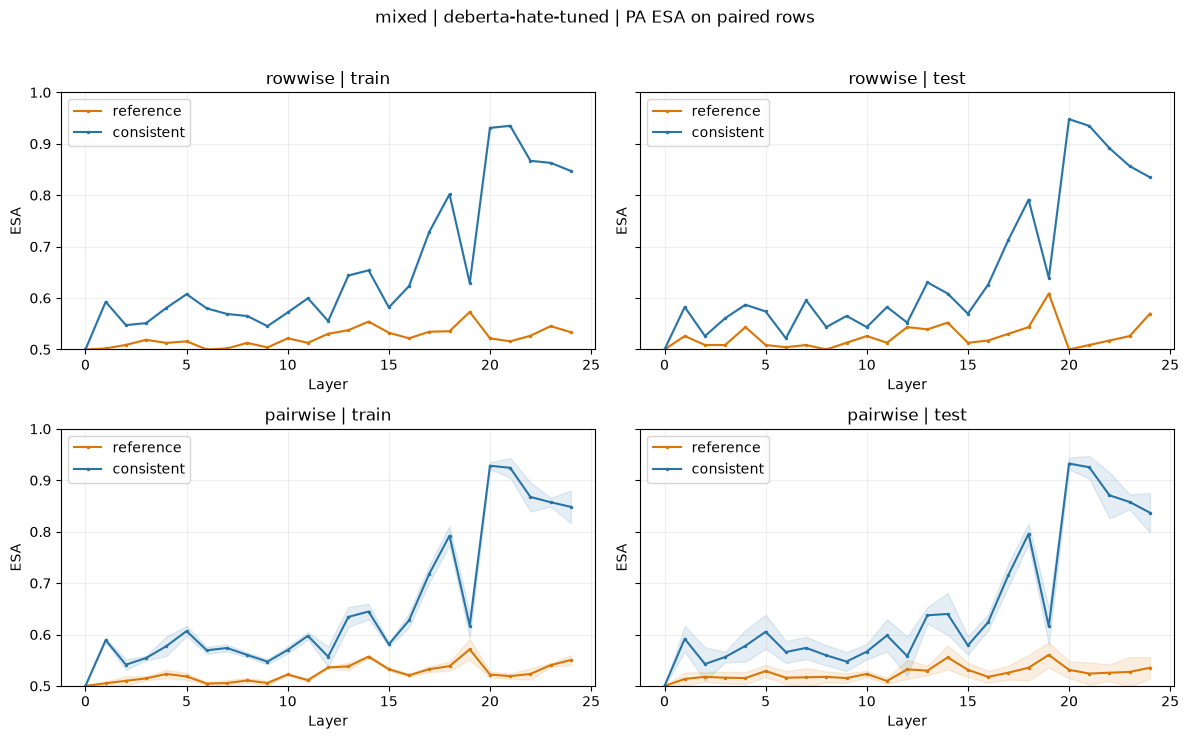

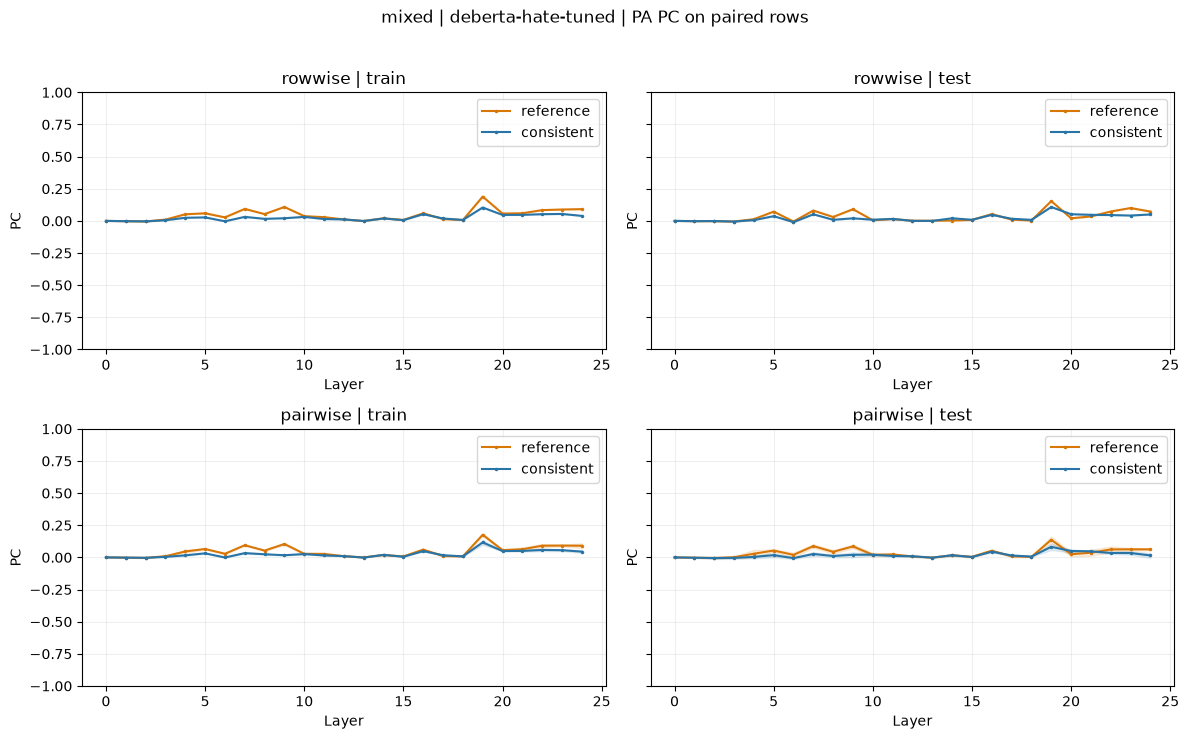

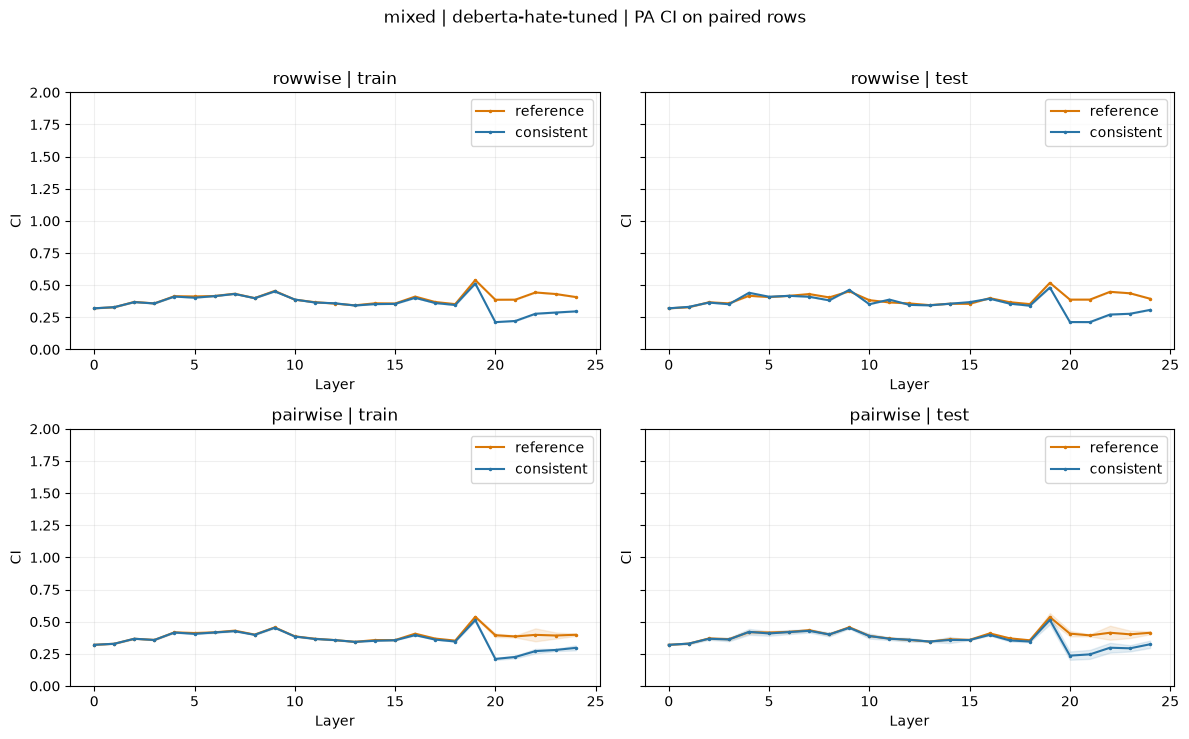

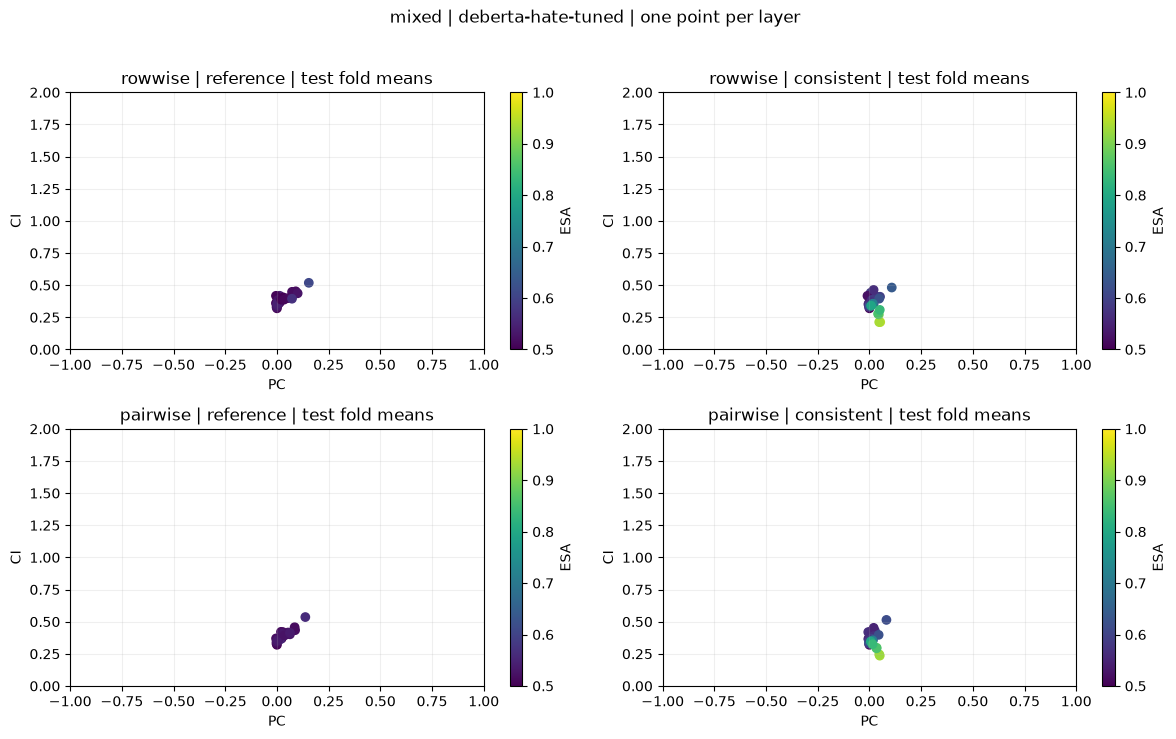

,dataset,model,protocol,layer,fold,split,pa_variant,n_pairs,counterpart_outside_split,esa,pc,ci
0,mixed,deberta-hate-tuned,rowwise,0,0,train,reference,507,113,0.500000,0.000000,0.320032
1,mixed,deberta-hate-tuned,rowwise,0,0,train,consistent,507,113,0.500000,0.000000,0.320032
2,mixed,deberta-hate-tuned,rowwise,0,0,test,reference,115,94,0.500000,0.000000,0.320032
3,mixed,deberta-hate-tuned,rowwise,0,0,test,consistent,115,94,0.500000,0.000000,0.320032
4,mixed,deberta-hate-tuned,rowwise,1,0,train,reference,507,113,0.501972,-0.001950,0.328286
...,...,...,...,...,...,...,...,...,...,...,...,...
595,mixed,deberta-hate-tuned,pairwise,24,3,test,consistent,124,0,0.879032,0.039753,0.294062
596,mixed,deberta-hate-tuned,pairwise,24,4,train,reference,498,0,0.559237,0.101150,0.400607
597,mixed,deberta-hate-tuned,pairwise,24,4,train,consistent,498,0,0.834337,0.051971,0.300222
598,mixed,deberta-hate-tuned,pairwise,24,4,test,reference,124,0,0.568548,0.063384,0.403315


In [12]:
plots.pa_comparison(mixed_results)
display(pd.concat([r["pa_metrics"] for r in mixed_results.values()], ignore_index=True))

## Геометрия hidden states: mixed и not

Реальные представления последнего сохранённого слоя: верхний ряд — mixed, нижний — not. Слева reference с четырьмя центрами, рядом CCS-consistent с сохранёнными train Yes/No центрами; справа распределения train-oriented CCS score. Ось X — фиксированное направление CCS, Y — одна общая ортогональная PCA-компонента для двух вариантов данного датасета; × обозначает среднее группы.

Row-wise сохраняет исторический выбор PA-пар и явно показывает число партнёров из train. Для pair-wise визуализируется **один выбранный fold**, по умолчанию 0, на его test-парах; разные fold не объединяются. PCA используется только для рисунка и не меняет probe или predictions.

rowwise not layer 24 fold 0 pairs 121 counterparts outside test 94
rowwise mixed layer 24 fold 0 pairs 115 counterparts outside test 94
pairwise not layer 24 fold 0 pairs 125 counterparts outside test 0
pairwise mixed layer 24 fold 0 pairs 125 counterparts outside test 0


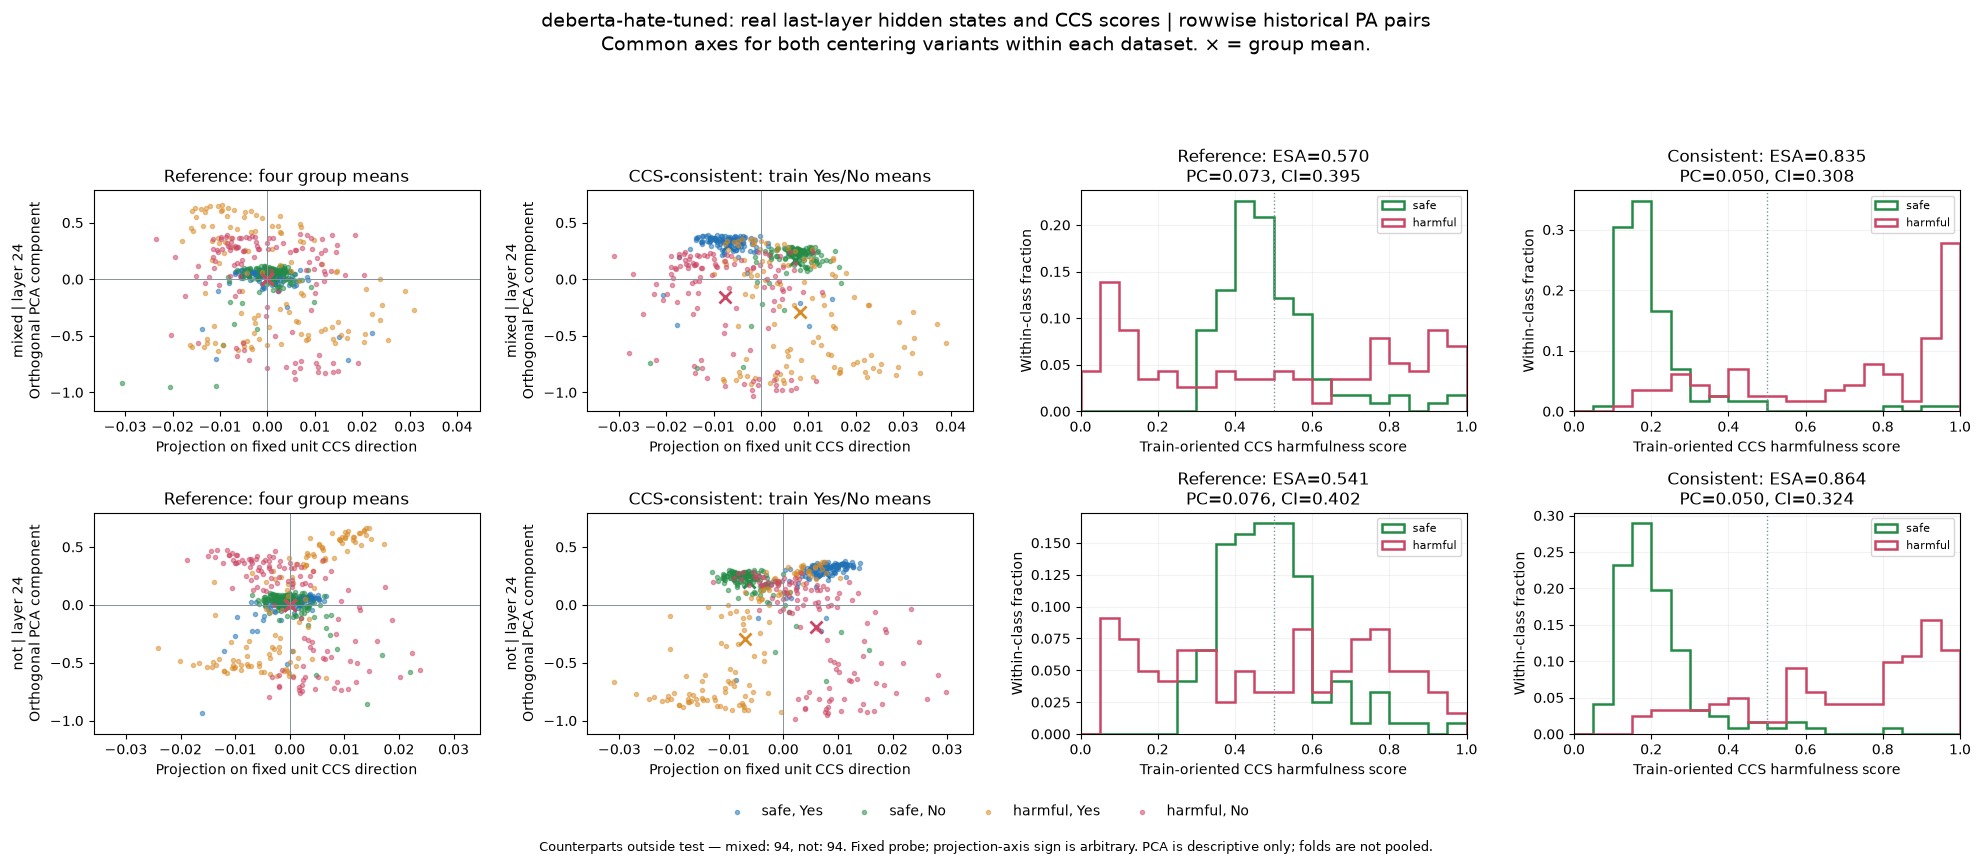

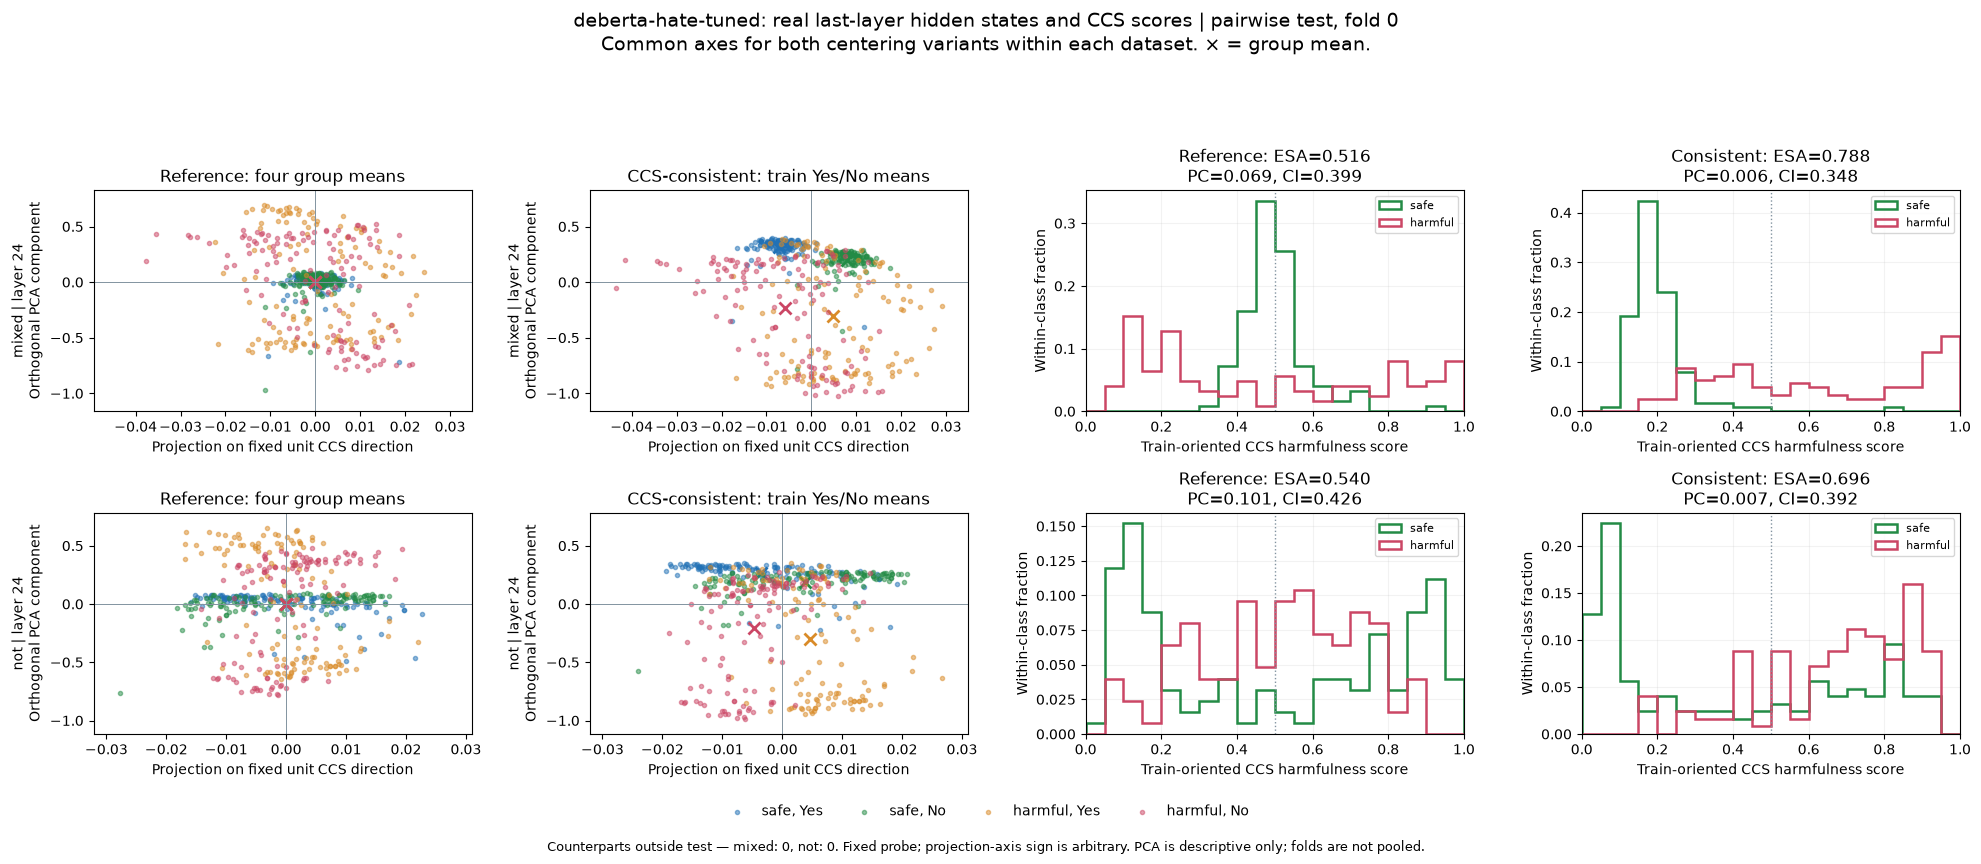

In [13]:
GEOMETRY_FOLD = 0
GEOMETRY_LAYER = None  # None = last saved layer
geometry = load_geometry({"not": not_results, "mixed": mixed_results},
                         layer=GEOMETRY_LAYER, fold=GEOMETRY_FOLD)
plots.hidden_geometry(geometry)
for protocol, datasets in geometry.items():
    for dataset, view in datasets.items():
        print(protocol, dataset, "layer", view["layer"], "fold", view["fold"],
              "pairs", view["n_pairs"], "counterparts outside test", view["counterpart_outside_split"])